<a href="https://colab.research.google.com/github/BeatrizCazatti/deep-learning/blob/main/2026_2_Practice_2_Implementing_LENET_5_architecture_using_Keras.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# *1 - Hands-on TensorFlow + Keras + LENET-5*

Implement and train several times using keras API your own LENET-5 implementation. The network should be trained to classify the images of the MNIST dataset.

## *1.1 - Load tensor flow*

In [ ]:
import tensorflow as tf

## *1.2 - Dataset preparation*

### *Import and prepare dataset*

Modified NIST (MNIST) is a database of handwritten digits. It encompasses a training set of 60,000 examples, and a test set of 10,000 examples. Images available in keras library are 28x28x1-sized.

The final part of the following code normalizes the training data to [0,1].

In [2]:
mnist = tf.keras.datasets.mnist

(x_train, y_train), (x_test, y_test) = mnist.load_data()
print ("Training set info:",x_train.shape)
print ("Train target info:",y_train.shape)
print ("Test set info:",x_test.shape)
print ("Test target info:",y_test.shape)

x_train_norm, x_test_norm = x_train / 255.0, x_test / 255.0

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training set info: (60000, 28, 28)
Train target info: (60000,)
Test set info: (10000, 28, 28)
Test target info: (10000,)


### *Show sample images*


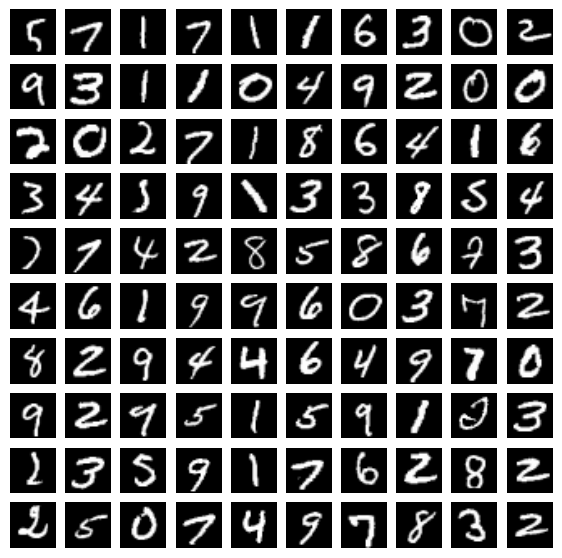

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 7))
for i in range(100,200):
  ax = plt.subplot(10, 10, i-99)
  plt.axis("off")
  plt.imshow(x_train_norm[i],interpolation='bilinear', cmap='gray')

### *1.3 - Create and Initialize LENET-5 Architecture*

Just as an example, the code bellow implements a single-hidden-layer perceptron using Keras functional architecture.



In [4]:
# Here goes a functional implementation of a MLP:
def mymlp_functional( hidd_neu = 128, hidd_act='relu',do_freq=0.2):
  inputs = tf.keras.layers.Input(shape=(28,28))
  x = tf.keras.layers.Flatten(input_shape=(28, 28))(inputs)
  x = tf.keras.layers.Dense(hidd_neu, activation=hidd_act) (x)
  x = tf.keras.layers.Dropout(do_freq) (x)
  outputs = tf.keras.layers.Dense(10, activation='softmax') (x)
  return tf.keras.models.Model(inputs, outputs, name='mymlp')


**Task 1** Implement using the Keras functional API the  [LENET-5 architecture](http://vision.stanford.edu/cs598_spring07/papers/Lecun98.pdf).

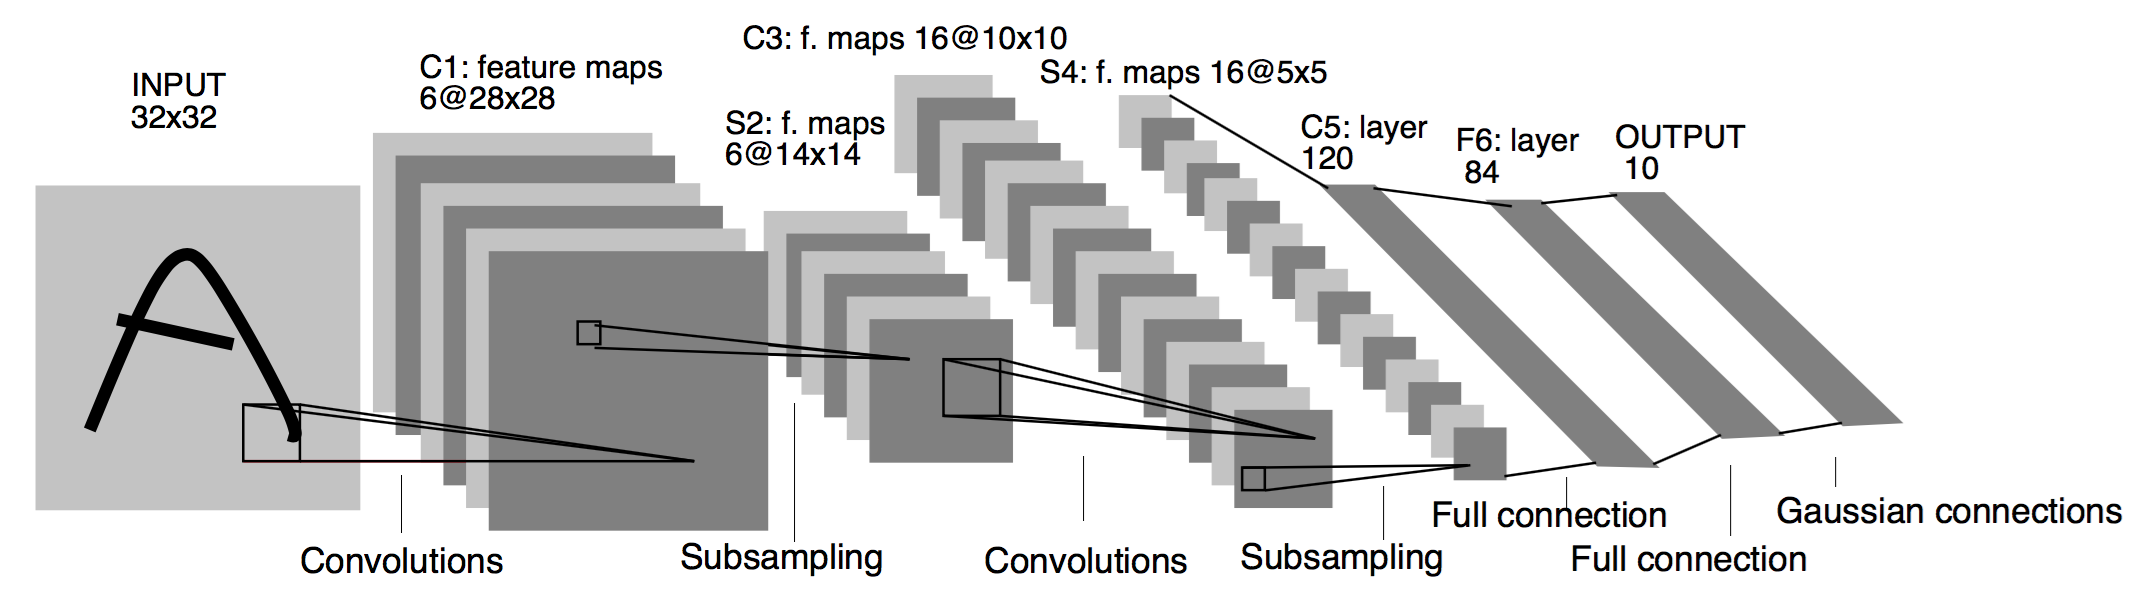

Here we will do the following modifications on the original LENET arquitecture:
* The input will be a 28 x 28 (MNIST) image.
* The first convolutional layer will produce feature maps with the same width and hight of the input images (use padding).
* All convolutional layers (tf.keras.layers.Conv2D(...)) should have RELU activation.
* All but the last fully conected layers should also have RELU activations. The output layer should have softmax activation.
* The subsampling operations should be implemented through MaxPooling (with filter size 2x2 and stride 2).
* We will drop the C5 layer, and substitute it by a MaxPooling followed by a flattening operation.

For the 2D-convolutional and maxpooling layers use the Keras functions [Conv2D](https://keras.io/api/layers/convolution_layers/convolution2d/) and [MaxPool2D](https://keras.io/api/layers/pooling_layers/max_pooling2d/), respectfully.

In addition, incorporate [batch normalization](https://keras.io/api/layers/normalization_layers/batch_normalization/) and dropout (after the fully conected layers) to your implementation.

For further information, consult [Keras layers API ](https://keras.io/api/layers/).

In [6]:
#Use this space to answer Task 1

def mylenet_functional(do_freq=0.2):
  inputs = tf.keras.layers.Input(shape=(28,28,1))

  x = tf.keras.layers.Conv2D(6, (5,5), padding='same', activation='relu')(inputs)
  x = tf.keras.layers.BatchNormalization()(x)
  x = tf.keras.layers.MaxPool2D(pool_size=(2,2), strides=2)(x)

  x = tf.keras.layers.Conv2D(16, (5,5), activation='relu')(x)
  x = tf.keras.layers.BatchNormalization()(x)
  x = tf.keras.layers.MaxPool2D(pool_size=(2,2), strides=2)(x)

  x = tf.keras.layers.MaxPool2D(pool_size=(2,2), strides=2)(x)
  x = tf.keras.layers.Flatten()(x)

  x = tf.keras.layers.Dense(120, activation='relu')(x)
  x = tf.keras.layers.BatchNormalization()(x)
  x = tf.keras.layers.Dropout(do_freq)(x)

  x = tf.keras.layers.Dense(84, activation='relu')(x)
  x = tf.keras.layers.BatchNormalization()(x)
  x = tf.keras.layers.Dropout(do_freq)(x)

  outputs = tf.keras.layers.Dense(10, activation='softmax')(x)

  return tf.keras.models.Model(inputs, outputs, name='mylenet')


model = mylenet_functional()

**Task 2** Calculate the number of parameters of the above model. Compare the estimatad values to the one provided by Model.summary().

> Add blockquote




In [7]:
#Use this space to answer Task 2
model.summary()

Model: "mylenet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 28, 28, 6)      │            24 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 6)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 10, 10, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 5, 5, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 2, 2, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 120)            │         7,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 120)            │           480 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 120)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 84)             │           336 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 84)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,290 (87.07 KB)

 Trainable params: 21,838 (85.30 KB)

 Non-trainable params: 452 (1.77 KB)

##*1.4 - Network training*

Remember the training process workflow:
1. Architecture setup
2. Network instantiation
3. Parameters initialization.
4. Training graph setup
5. Paramenters optimization
6. Evaluation

Details can be found in the [keras documentation](https://keras.io/api/models/model_training_apis/).

**Task 3**: Train the model for 50 epochs, using the Adam optimizer.

In [8]:
# Put you code for Task 3 here
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    x_train_norm,
    y_train,
    epochs=50,
    validation_split=0.1
)

test_loss, test_acc = model.evaluate(x_test_norm, y_test)

print("Test loss:", test_loss)
print("Test accuracy:", test_acc)

Epoch 1/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 24s 8ms/step - accuracy: 0.9094 - loss: 0.2924 - val_accuracy: 0.9758 - val_loss: 0.0791
Epoch 2/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9672 - loss: 0.1079 - val_accuracy: 0.9818 - val_loss: 0.0607
Epoch 3/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9735 - loss: 0.0855 - val_accuracy: 0.9843 - val_loss: 0.0537
Epoch 4/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9764 - loss: 0.0750 - val_accuracy: 0.9885 - val_loss: 0.0435
Epoch 5/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9788 - loss: 0.0666 - val_accuracy: 0.9880 - val_loss: 0.0439
Epoch 6/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9812 - loss: 0.0608 - val_accuracy: 0.9842 - val_loss: 0.0563
Epoch 7/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9830 - loss: 0.0555 - val_accuracy: 0.9875 - val_loss: 0.0404
Epoch 8/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9829 - loss: 0.0521 -

**Task 4**: Analyse the training history graph. In your opinion, which was the "best" epoch? Why?

Acredito que a "melhor" época foi a 21 se quisermos diminuir ao máximo a validation loss, no exemplo, seu valor chegou a 0,0324. Mas se adotarmos como critério a época que atingiu a maior validation accuracy, podemos considerar a como melhor a 31 que chegou a 99,28%.


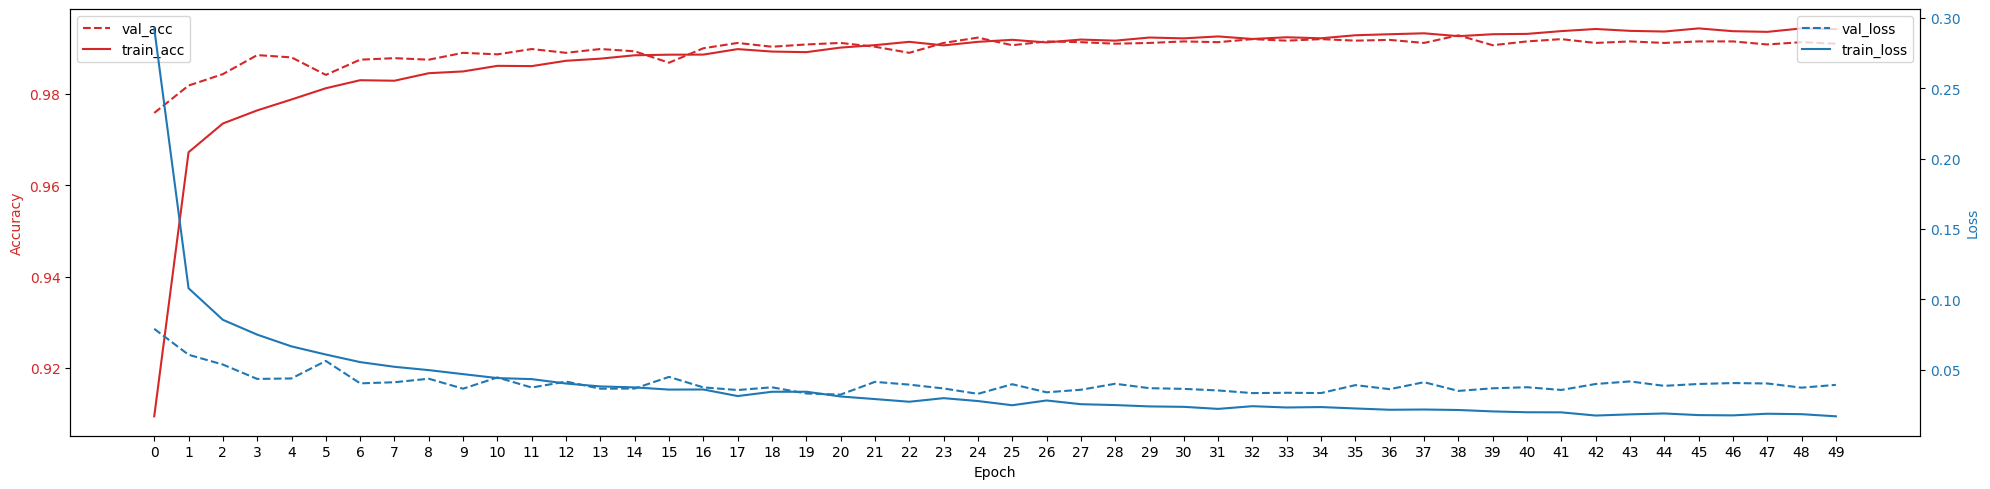

In [12]:
import numpy as np

H = history
EPOCHS = 50

fig, ax1 = plt.subplots(figsize=(20, 5))

color = 'tab:red'
ax1.set_xlabel('Epoch')
ax1.set_xticks(np.arange(EPOCHS))
ax1.set_ylabel('Accuracy', color=color)
ax1.plot(H.history["val_accuracy"], '--', label="val_acc", color=color)
ax1.plot(H.history["accuracy"], label="train_acc", color=color)
ax1.tick_params(axis='y', labelcolor=color)
ax1.legend()

ax2 = ax1.twinx()  # instantiate a second axes that shares the same x-axis

color = 'tab:blue'
ax2.set_ylabel('Loss', color=color)  # we already handled the x-label with ax1
ax2.plot(H.history["val_loss"], '--', label="val_loss", color=color)
ax2.plot(H.history["loss"], label="train_loss",color=color)
ax2.tick_params(axis='y', labelcolor=color)
ax2.legend()

fig.tight_layout()  # otherwise the right y-label is slightly clipped
plt.show()

**Task 5**: Remove the Batch Normalization and Dropout layers from the architecture and train the network again for 50 epochs, using the Adam optimizer.

In [16]:
#Put your code for Task 5 here

def mylenet_functional_2(do_freq=0.2):
  inputs = tf.keras.layers.Input(shape=(28,28,1))

  x = tf.keras.layers.Conv2D(6, (5,5), padding='same', activation='relu')(inputs)
  x = tf.keras.layers.MaxPool2D(pool_size=(2,2), strides=2)(x)

  x = tf.keras.layers.Conv2D(16, (5,5), activation='relu')(x)
  x = tf.keras.layers.MaxPool2D(pool_size=(2,2), strides=2)(x)

  x = tf.keras.layers.MaxPool2D(pool_size=(2,2), strides=2)(x)
  x = tf.keras.layers.Flatten()(x)

  x = tf.keras.layers.Dense(120, activation='relu')(x)
  x = tf.keras.layers.Dense(84, activation='relu')(x)

  outputs = tf.keras.layers.Dense(10, activation='softmax')(x)

  return tf.keras.models.Model(inputs, outputs, name='mylenet')


model_2 = mylenet_functional_2()
model_2.summary()

model_2.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_2 = model_2.fit(
    x_train_norm,
    y_train,
    epochs=50,
    validation_split=0.1
)

test_loss, test_acc = model_2.evaluate(x_test_norm, y_test)

print("Test loss:", test_loss)
print("Test accuracy:", test_acc)

Model: "mylenet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 28, 28, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 14, 14, 6)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 5, 5, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 2, 2, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 120)            │         7,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,386 (83.54 KB)

 Trainable params: 21,386 (83.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9189 - loss: 0.2640 - val_accuracy: 0.9772 - val_loss: 0.0799
Epoch 2/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9740 - loss: 0.0837 - val_accuracy: 0.9820 - val_loss: 0.0630
Epoch 3/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9799 - loss: 0.0647 - val_accuracy: 0.9832 - val_loss: 0.0553
Epoch 4/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9830 - loss: 0.0545 - val_accuracy: 0.9862 - val_loss: 0.0449
Epoch 5/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9859 - loss: 0.0454 - val_accuracy: 0.9905 - val_loss: 0.0388
Epoch 6/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9876 - loss: 0.0390 - val_accuracy: 0.9872 - val_loss: 0.0450
Epoch 7/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9883 - loss: 0.0348 - val_accuracy: 0.9880 - val_loss: 0.0483
Epoch 8/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9891 - loss: 0.0320 -

**Task 6**: Analyse the training history graph. In your opinion, which was the "best" epoch now? Why?

Se considerarmos validation loss como critério, a "melhor" época foi a 5 em que essa perda atingiu o menor valor de 0,0388, com acurácia de validação de 99,05%. A época 25 apresenta a maior da validation accuracy de 99,10%, porém a sua perda é maior 0,0507.

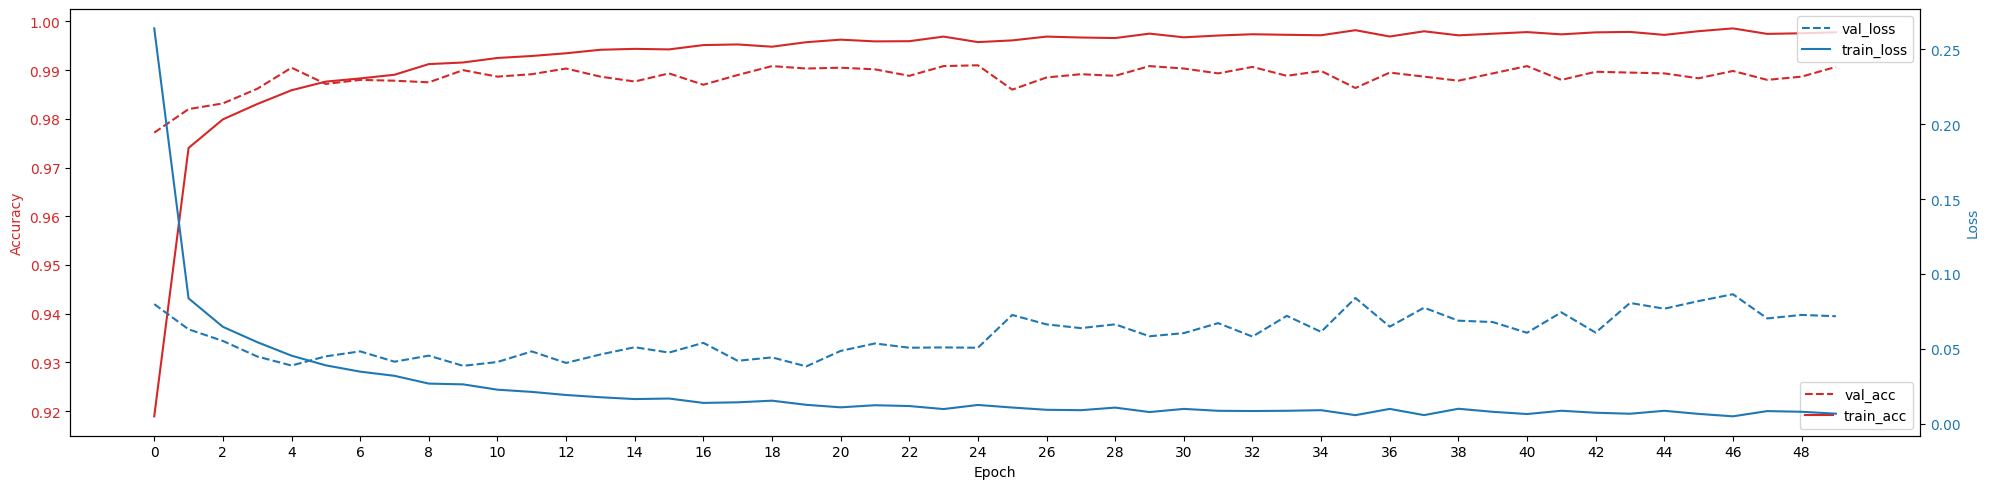

In [17]:
#Put your code for Task 6 here

import numpy as np
import matplotlib.pyplot as plt

H = history_2
EPOCHS = 50

fig, ax1 = plt.subplots(figsize=(20, 5))

color = 'tab:red'
ax1.set_xlabel('Epoch')
ax1.set_xticks(np.arange(0, EPOCHS, 2))
ax1.set_ylabel('Accuracy', color=color)
ax1.plot(H.history["val_accuracy"], '--', label="val_acc", color=color)
ax1.plot(H.history["accuracy"], label="train_acc", color=color)
ax1.tick_params(axis='y', labelcolor=color)
ax1.legend(loc='lower right')

ax2 = ax1.twinx()

color = 'tab:blue'
ax2.set_ylabel('Loss', color=color)
ax2.plot(H.history["val_loss"], '--', label="val_loss", color=color)
ax2.plot(H.history["loss"], label="train_loss", color=color)
ax2.tick_params(axis='y', labelcolor=color)
ax2.legend(loc='upper right')

fig.tight_layout()
plt.show()


**Task 7**: Train the network implemented in Task 1 with the [Early Stopping callback](https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/EarlyStopping). The patience parameter should be 5 epochs. Use a number of epochs so that the best epoch is not the last one.

In [18]:
#Put your code for Task 7 here

# This is only the callback function
es_callback = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    min_delta=0,
    patience=5,
    verbose=0,
    mode='auto',
    baseline=None,
    restore_best_weights=False,
    start_from_epoch=0
)

model = mylenet_functional()

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    x_train_norm,
    y_train,
    epochs=50,
    validation_split=0.1,
    callbacks=[es_callback]
)

test_loss, test_acc = model.evaluate(x_test_norm, y_test)

print("Test loss:", test_loss)
print("Test accuracy:", test_acc)
print("Epochs trained:", len(history.history['loss']))
print("Best epoch:", np.argmin(history.history['val_loss']) + 1)

Epoch 1/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 15s 6ms/step - accuracy: 0.9066 - loss: 0.2971 - val_accuracy: 0.9743 - val_loss: 0.0747
Epoch 2/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9616 - loss: 0.1238 - val_accuracy: 0.9852 - val_loss: 0.0537
Epoch 3/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9709 - loss: 0.0962 - val_accuracy: 0.9820 - val_loss: 0.0606
Epoch 4/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9753 - loss: 0.0811 - val_accuracy: 0.9818 - val_loss: 0.0581
Epoch 5/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9771 - loss: 0.0747 - val_accuracy: 0.9860 - val_loss: 0.0457
Epoch 6/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9792 - loss: 0.0662 - val_accuracy: 0.9818 - val_loss: 0.0591
Epoch 7/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9809 - loss: 0.0602 - val_accuracy: 0.9885 - val_loss: 0.0408
Epoch 8/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9814 - loss: 0.0589 -

**Task 8**: Analyse the training history graph. Which was the "best" epoch?

A "melhor" época foi a 12 com o menor valor de validation loss de 0.0389 e maior validation accuracy de 98,77%. Então, o treinamento foi interrompido na época 17 porque não houve melhora na validation loss durante cinco épocas consecutivas.

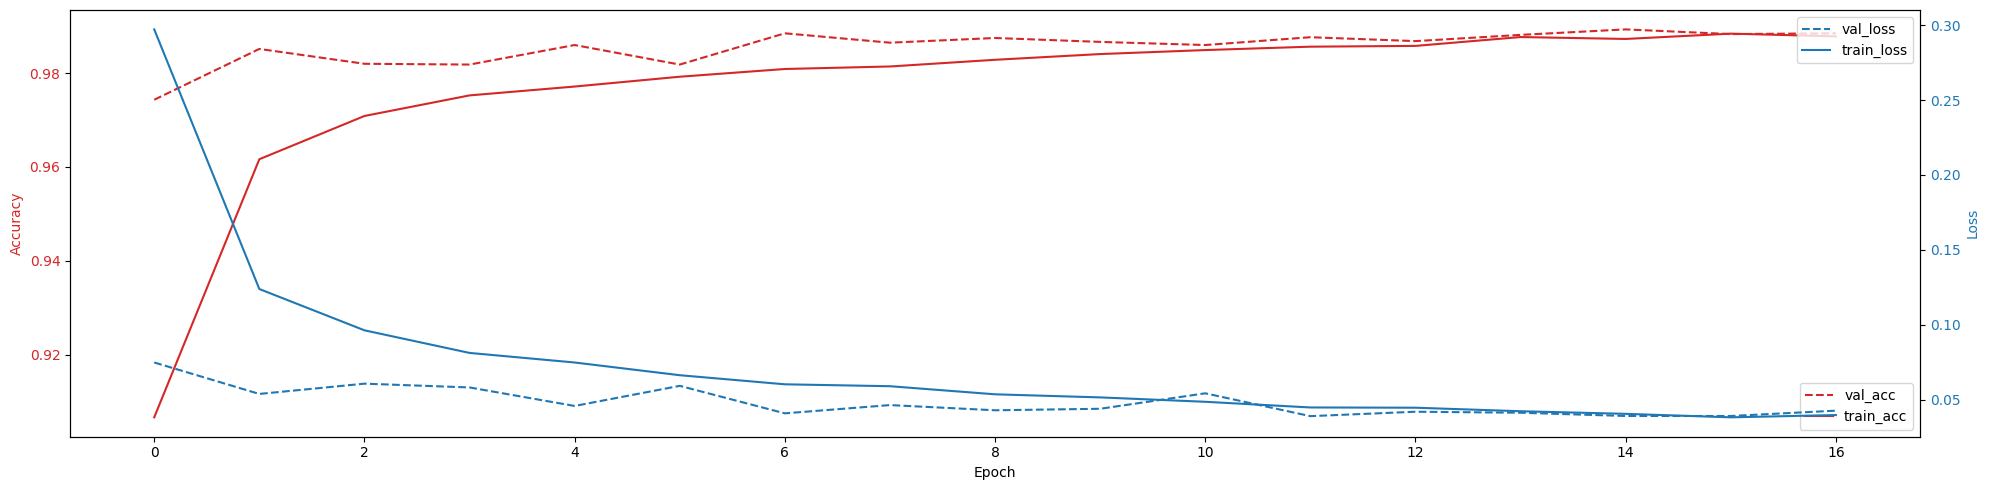

In [20]:
#Put your code for Task 8 here
H = history
EPOCHS = len(H.history['loss'])

fig, ax1 = plt.subplots(figsize=(20, 5))

color = 'tab:red'
ax1.set_xlabel('Epoch')
ax1.set_xticks(np.arange(0, EPOCHS, 2))
ax1.set_ylabel('Accuracy', color=color)
ax1.plot(H.history["val_accuracy"], '--', label="val_acc", color=color)
ax1.plot(H.history["accuracy"], label="train_acc", color=color)
ax1.tick_params(axis='y', labelcolor=color)
ax1.legend(loc='lower right')

ax2 = ax1.twinx()

color = 'tab:blue'
ax2.set_ylabel('Loss', color=color)
ax2.plot(H.history["val_loss"], '--', label="val_loss", color=color)
ax2.plot(H.history["loss"], label="train_loss", color=color)
ax2.tick_params(axis='y', labelcolor=color)
ax2.legend(loc='upper right')

fig.tight_layout()
plt.show()

##*2 - Rigorous evaluation*
Tasks 9 to 15 will introduce yourself to a more thorought evaluation of the network trained in **Task 7**. It is a really important need for ensuring network quality.

**Task 9**: Obtain the test set [confusion matrix](https://gsp.humboldt.edu/olm/Courses/GSP_216/lessons/accuracy/metrics.html) for the above trained network. Consider using the confusion_matrix and ConfusionMatrixDisplay from the Scikit Learn library.



313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


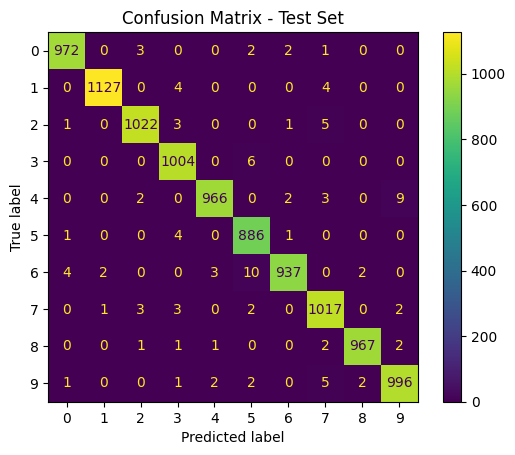

In [21]:
#Put your code for Task 9 here
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_pred_prob = model.predict(x_test_norm)

y_pred = np.argmax(y_pred_prob, axis=1)

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10)
)

disp.plot()
plt.title('Confusion Matrix - Test Set')
plt.show()

**Task 10**: Present the [overall accuracy](https://gsp.humboldt.edu/olm/Courses/GSP_216/lessons/accuracy/metrics.html).

In [23]:
#Put your code for Task 10 here
from sklearn.metrics import accuracy_score

y_pred_prob = model.predict(x_test_norm)
y_pred = np.argmax(y_pred_prob, axis=1)

overall_accuracy = accuracy_score(y_test, y_pred)

print("Overall Accuracy:", overall_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Overall Accuracy: 0.9894


**Task 11**: Present the [errors of omission and commission](https://gsp.humboldt.edu/olm/Courses/GSP_216/lessons/accuracy/metrics.html).

In [24]:
#Put your code for Task 11 here
import pandas as pd

actual_totals = cm.sum(axis=1)

predicted_totals = cm.sum(axis=0)

correct = np.diag(cm)


omission_errors = (actual_totals - correct) / actual_totals
commission_errors = (predicted_totals - correct) / predicted_totals

results = pd.DataFrame({
    'Digit': np.arange(10),
    'Omission Error (%)': omission_errors * 100,
    'Commission Error (%)': commission_errors * 100
})

print(results.round(2))

   Digit  Omission Error (%)  Commission Error (%)
0      0                0.82                  0.72
1      1                0.70                  0.27
2      2                0.97                  0.87
3      3                0.59                  1.57
4      4                1.63                  0.62
5      5                0.67                  2.42
6      6                2.19                  0.64
7      7                1.07                  1.93
8      8                0.72                  0.41
9      9                1.29                  1.29


**Task 12**: Present [user's  and producer's accuracy](https://gsp.humboldt.edu/olm/Courses/GSP_216/lessons/accuracy/metrics.html).

In [25]:
#Put your code for Task 12 here

correct = np.diag(cm)

predicted_totals = cm.sum(axis=0)

actual_totals = cm.sum(axis=1)

users_accuracy = correct / predicted_totals

producers_accuracy = correct / actual_totals

results = pd.DataFrame({
    'Digit': np.arange(10),
    "User's Accuracy (%)": users_accuracy * 100,
    "Producer's Accuracy (%)": producers_accuracy * 100
})

print(results.round(2))


   Digit  User's Accuracy (%)  Producer's Accuracy (%)
0      0                99.28                    99.18
1      1                99.73                    99.30
2      2                99.13                    99.03
3      3                98.43                    99.41
4      4                99.38                    98.37
5      5                97.58                    99.33
6      6                99.36                    97.81
7      7                98.07                    98.93
8      8                99.59                    99.28
9      9                98.71                    98.71


**Task 13**: Obtain the [Kappa](https://gsp.humboldt.edu/olm/Courses/GSP_216/lessons/accuracy/metrics.html) value.

In [26]:
#Put your code for Task 13 here
from sklearn.metrics import cohen_kappa_score

kappa = cohen_kappa_score(y_test, y_pred)

print("Kappa:", kappa)

Kappa: 0.9882177885760633


##*3 - Optimizers*

Evaluate the impact of optimizer's choice during training process.


**Task 14**: Train the network implemented in Task 7 (with early stopping) varying the [optimizers](https://keras.io/api/optimizers/#available-optimizers). Save the training history for each training, then plot histories of both losses and accuracies in the training set. Also compare the training and test final accuracy values obtained using each optimizer.  

Click here for [tf.keras.optimizers](https://www.tensorflow.org/api_docs/python/tf/keras/optimizers) documentation. There you may find the following variants:

  * SGD
  * RMSprop
  * Adam
  * Adadelta
  * Adagrad




Epoch 1/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 14s 6ms/step - accuracy: 0.8843 - loss: 0.3792 - val_accuracy: 0.9727 - val_loss: 0.0942
Epoch 2/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9503 - loss: 0.1625 - val_accuracy: 0.9793 - val_loss: 0.0685
Epoch 3/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9616 - loss: 0.1288 - val_accuracy: 0.9808 - val_loss: 0.0587
Epoch 4/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9676 - loss: 0.1082 - val_accuracy: 0.9832 - val_loss: 0.0559
Epoch 5/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9709 - loss: 0.0976 - val_accuracy: 0.9822 - val_loss: 0.0529
Epoch 6/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9723 - loss: 0.0896 - val_accuracy: 0.9838 - val_loss: 0.0469
Epoch 7/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9749 - loss: 0.0817 - val_accuracy: 0.9845 - val_loss: 0.0521
Epoch 8/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9764 - loss: 0.0766 -

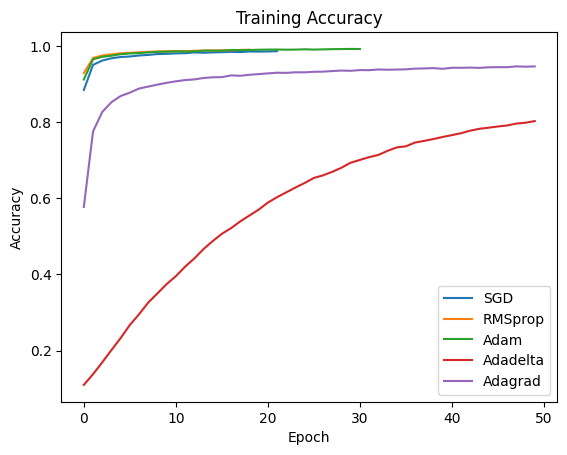

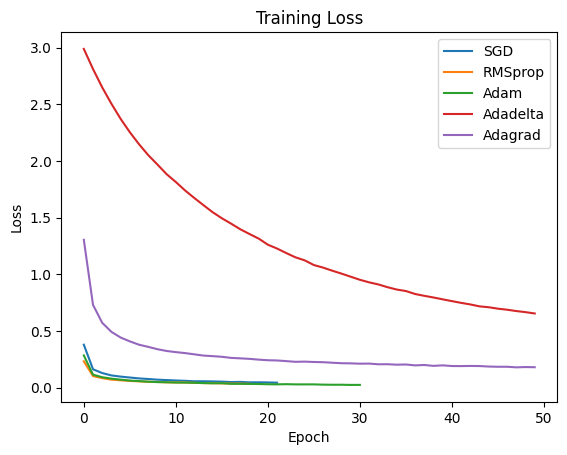

In [30]:
# Put your code here for Task 14

optimizers = {
    'SGD': tf.keras.optimizers.SGD(),
    'RMSprop': tf.keras.optimizers.RMSprop(),
    'Adam': tf.keras.optimizers.Adam(),
    'Adadelta': tf.keras.optimizers.Adadelta(),
    'Adagrad': tf.keras.optimizers.Adagrad()
}

histories = {}
results = []

for name, opt in optimizers.items():

    model = mylenet_functional()

    model.compile(
        optimizer=opt,
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    es_callback = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5
    )

    H = model.fit(
        x_train_norm, y_train,
        epochs=50,
        validation_split=0.1,
        callbacks=[es_callback]
    )

    histories[name] = H.history

    best_epoch = H.history['val_loss'].index(
        min(H.history['val_loss'])
    ) + 1

    train_acc = H.history['accuracy'][-1]
    test_loss, test_acc = model.evaluate(
        x_test_norm, y_test, verbose=0
    )

    results.append([
        name,
        best_epoch,
        train_acc * 100,
        test_acc * 100
    ])

print(pd.DataFrame(
    results,
    columns=[
        'Optimizer',
        'Best Epoch',
        'Train Accuracy (%)',
        'Test Accuracy (%)'
    ]
).round(2))

# Gráfico das acurácias de treinamento
for name, H in histories.items():
    plt.plot(H['accuracy'], label=name)

plt.title('Training Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Gráfico das perdas de treinamento
for name, H in histories.items():
    plt.plot(H['loss'], label=name)

plt.title('Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

**Task 15** Put your outcomes here in the form of a table. The table should show the best epoch and the overall accuracy obtained on the test data, for each optimizer.

In [31]:
print(pd.DataFrame(
    [[r[0], r[1], r[3]] for r in results],
    columns=[
        'Optimizer',
        'Best Epoch',
        'Test Accuracy (%)'
    ]
).round(2).to_string(index=False))

Optimizer  Best Epoch  Test Accuracy (%)
      SGD          17              98.83
  RMSprop          14              98.95
     Adam          26              99.07
 Adadelta          50              86.80
  Adagrad          50              96.77
